# CART Models: Delivery Time Prediction

This notebook uses a **synthetic, realistic delivery dataset with 10,000 rows**.

- **Classification:** Predict `Late_Delivery` (Yes/No) using a CART Decision Tree Classifier and Gini impurity.
- **Regression:** Predict `Delivery_Time_Minutes` using a CART Decision Tree Regressor and squared error.

The records are generated for learning purposes; they are not real company or customer data.

## 1. Import libraries

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the dataset
Keep `delivery_time_dataset_10000.csv` in the same folder as this notebook.

In [24]:
df = pd.read_csv("delivery_time_dataset.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (10000, 11)


,Distance_km,Weather,Traffic_Level,Vehicle_Type,City_Tier,Order_Hour,Package_Weight_kg,Courier_Experience_Years,Weekend_Order,Delivery_Time_Minutes,Late_Delivery
0,30.99,Rain,Medium,Car,Tier 1,8,4.16,2,No,113.7,Yes
1,15.08,Clear,Medium,Van,Tier 2,20,13.08,10,No,66.9,Yes
2,21.83,Rain,Low,Bike,Tier 3,9,4.17,0,No,81.6,Yes
3,5.79,Cloudy,Low,Bike,Tier 1,19,7.99,3,No,47.2,No
4,18.92,Clear,Medium,Scooter,Tier 1,8,11.91,6,Yes,78.8,Yes


## 3. Explore the dataset

In [25]:
df.info()
print("\\nMissing values:")
display(df.isnull().sum())
print("\\nTarget distribution:")
display(df["Late_Delivery"].value_counts())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Distance_km               10000 non-null  float64
 1   Weather                   10000 non-null  str    
 2   Traffic_Level             10000 non-null  str    
 3   Vehicle_Type              10000 non-null  str    
 4   City_Tier                 10000 non-null  str    
 5   Order_Hour                10000 non-null  int64  
 6   Package_Weight_kg         10000 non-null  float64
 7   Courier_Experience_Years  10000 non-null  int64  
 8   Weekend_Order             10000 non-null  str    
 9   Delivery_Time_Minutes     10000 non-null  float64
 10  Late_Delivery             10000 non-null  str    
dtypes: float64(3), int64(2), str(6)
memory usage: 1.1 MB
\nMissing values:


Distance_km                 0
Weather                     0
Traffic_Level               0
Vehicle_Type                0
City_Tier                   0
Order_Hour                  0
Package_Weight_kg           0
Courier_Experience_Years    0
Weekend_Order               0
Delivery_Time_Minutes       0
Late_Delivery               0
dtype: int64

\nTarget distribution:


Late_Delivery
Yes    7024
No     2976
Name: count, dtype: int64

,Distance_km,Order_Hour,Package_Weight_kg,Courier_Experience_Years,Delivery_Time_Minutes
count,10000.000000,10000.000000,10000.0000,10000.000000,10000.00000
mean,17.987821,15.039100,9.1166,5.004400,74.34982
std,9.827907,4.299653,5.1054,3.136872,22.75430
min,1.000000,8.000000,0.2000,0.000000,12.00000
25%,9.500000,11.000000,4.6600,2.000000,56.70000
50%,17.890000,15.000000,9.1600,5.000000,74.40000
75%,26.490000,19.000000,13.4300,8.000000,92.00000
max,35.000000,22.000000,18.0000,10.000000,141.20000


## 4. Basic preprocessing

In [26]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().copy()

Missing values: 0
Duplicate rows: 0


## 5. Exploratory data analysis

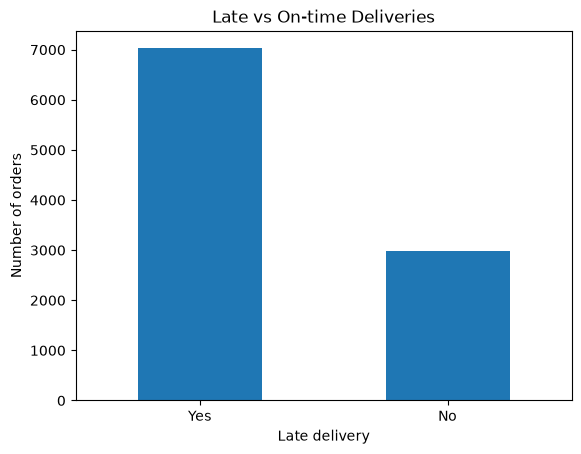

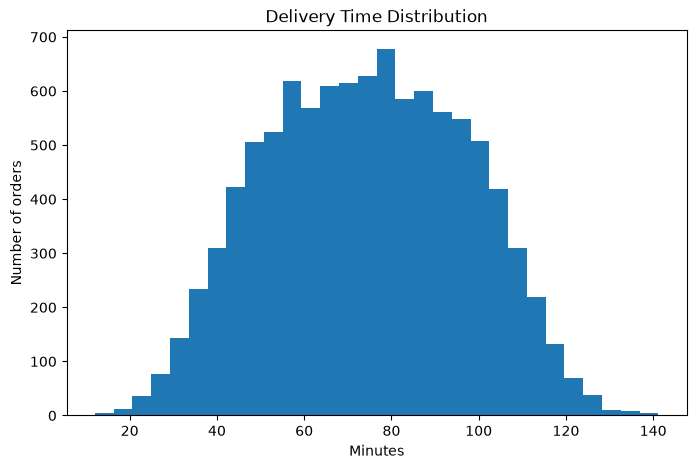

In [27]:
df["Late_Delivery"].value_counts().plot(kind="bar")
plt.title("Late vs On-time Deliveries")
plt.xlabel("Late delivery")
plt.ylabel("Number of orders")
plt.xticks(rotation=0)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df["Delivery_Time_Minutes"], bins=30)
plt.title("Delivery Time Distribution")
plt.xlabel("Minutes")
plt.ylabel("Number of orders")
plt.show()

# Part A: CART Classification

## 6. Select features and target

We exclude `Delivery_Time_Minutes` because it is used to create the `Late_Delivery` label. Including it would cause target leakage.

In [28]:
features = [
    "Distance_km", "Weather", "Traffic_Level", "Vehicle_Type", "City_Tier",
    "Order_Hour", "Package_Weight_kg", "Courier_Experience_Years", "Weekend_Order"
]
X = df[features]
y = df["Late_Delivery"]

categorical = ["Weather", "Traffic_Level", "Vehicle_Type", "City_Tier", "Weekend_Order"]
numeric = ["Distance_km", "Order_Hour", "Package_Weight_kg", "Courier_Experience_Years"]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("numeric", "passthrough", numeric)
])

## 7. Split into training and testing sets

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 8000
Testing rows: 2000


## 8. Build and train the CART classifier

`criterion="gini"` uses Gini impurity. `max_depth` and `min_samples_leaf` help control overfitting.

In [30]:
cart_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        criterion="gini", max_depth=6, min_samples_leaf=10, random_state=42
    ))
])
cart_classifier.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Distance_km','Weather','Traffic_Level',...,'Package_Weight_kg', 'Courier_Experience_Years','Weekend_Order']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'

## 9. Predict and evaluate classification

In [31]:
y_pred = cart_classifier.predict(X_test)
display(pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred}).head(15))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred, labels=["No", "Yes"]))
print("\\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

,Actual,Predicted
0,Yes,Yes
1,Yes,Yes
2,Yes,Yes
3,No,No
4,No,No
5,Yes,Yes
6,No,No
7,Yes,Yes
8,Yes,Yes
9,Yes,Yes


Accuracy: 0.899
\nConfusion matrix:
[[ 526   69]
 [ 133 1272]]
\nClassification report:
              precision    recall  f1-score   support

          No       0.80      0.88      0.84       595
         Yes       0.95      0.91      0.93      1405

    accuracy                           0.90      2000
   macro avg       0.87      0.89      0.88      2000
weighted avg       0.90      0.90      0.90      2000



## 10. Visualize the classification tree

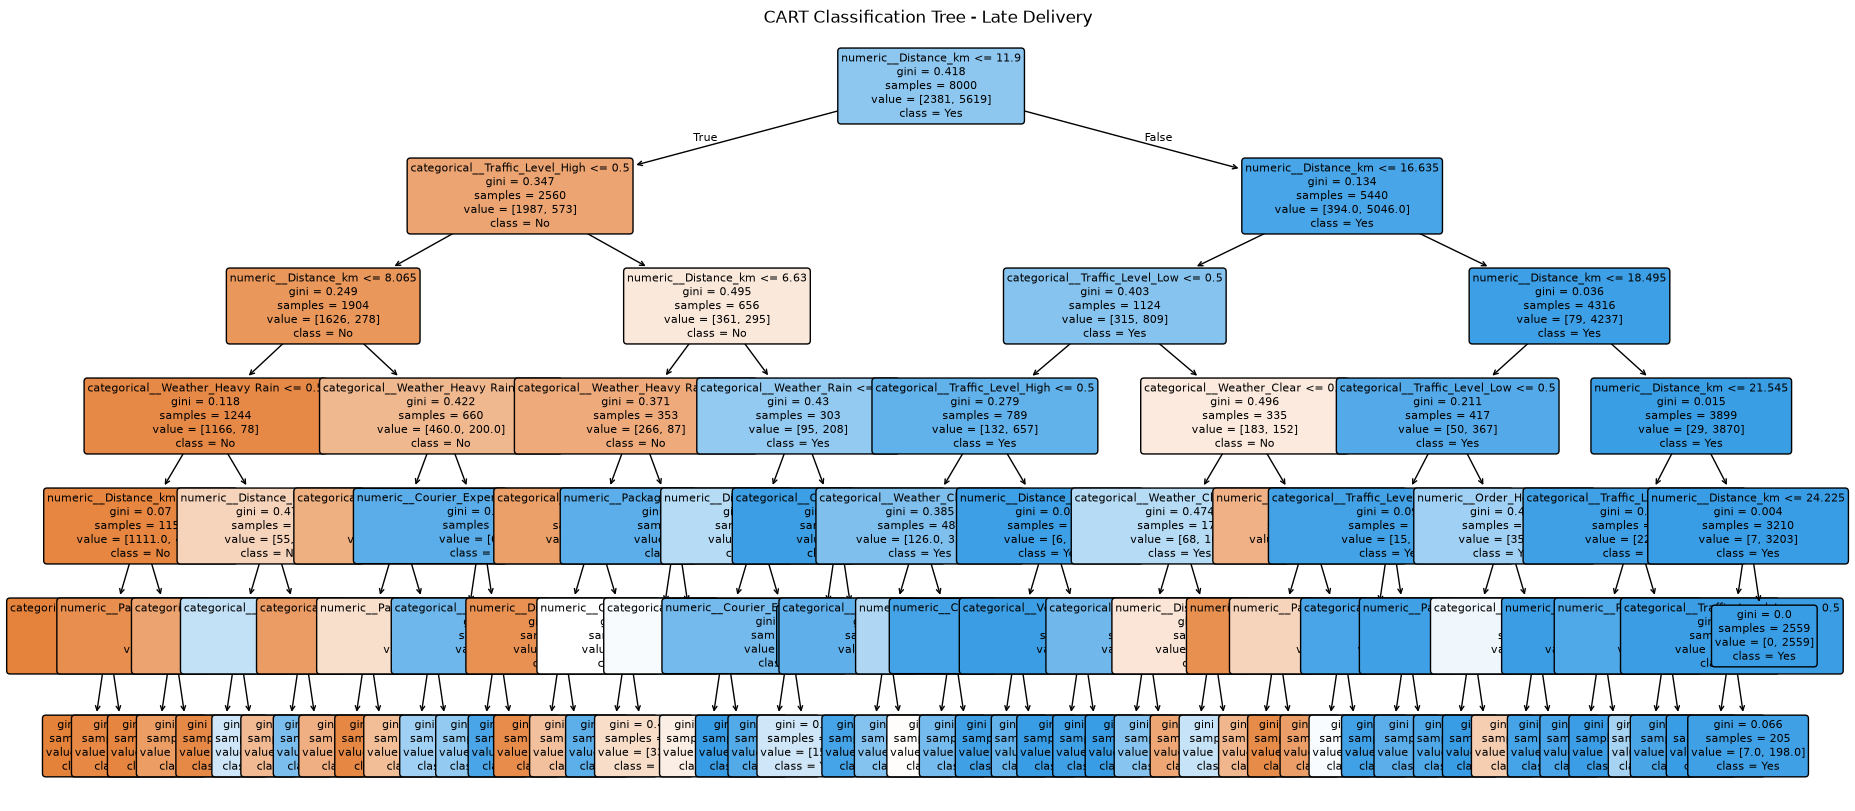

In [32]:
classifier_features = cart_classifier.named_steps["preprocessor"].get_feature_names_out()
classifier_tree = cart_classifier.named_steps["model"]

plt.figure(figsize=(22, 10))
plot_tree(classifier_tree, feature_names=classifier_features,
          class_names=classifier_tree.classes_, filled=True,
          rounded=True, fontsize=8)
plt.title("CART Classification Tree - Late Delivery")
plt.show()

## 11. Classification feature importance

numeric__Distance_km               0.820980
categorical__Traffic_Level_High    0.045503
categorical__Traffic_Level_Low     0.037789
categorical__Weather_Heavy Rain    0.031651
categorical__Weather_Rain          0.013473
categorical__City_Tier_Tier 1      0.012763
categorical__Weather_Clear         0.012152
numeric__Package_Weight_kg         0.008540
categorical__Weather_Cloudy        0.006628
numeric__Order_Hour                0.005435
dtype: float64

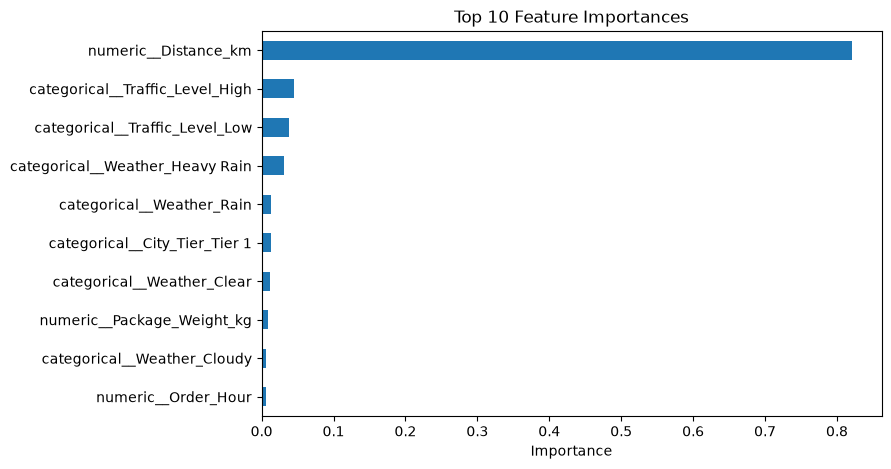

In [33]:
importance = pd.Series(
    classifier_tree.feature_importances_, index=classifier_features
).sort_values(ascending=False)

display(importance.head(10))
importance.head(10).sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.show()

# Part B: CART Regression

## 12. Select regression features and target

The regression model predicts delivery time in minutes. We exclude both target columns from the inputs.

In [34]:
X_reg = df[features]
y_reg = df["Delivery_Time_Minutes"]

regression_preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("numeric", "passthrough", numeric)
])

## 13. Split regression data

In [35]:
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)
print("Training rows:", len(X_reg_train))
print("Testing rows:", len(X_reg_test))

Training rows: 8000
Testing rows: 2000


## 14. Build and train the CART regressor

In [36]:
cart_regressor = Pipeline([
    ("preprocessor", regression_preprocessor),
    ("model", DecisionTreeRegressor(
        criterion="squared_error", max_depth=6,
        min_samples_leaf=10, random_state=42
    ))
])
cart_regressor.fit(X_reg_train, y_reg_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Distance_km','Weather','Traffic_Level',...,'Package_Weight_kg', 'Courier_Experience_Years','Weekend_Order']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be auto

## 15. Predict and evaluate regression

In [37]:
y_reg_pred = cart_regressor.predict(X_reg_test)
display(pd.DataFrame({
    "Actual Minutes": y_reg_test.values,
    "Predicted Minutes": y_reg_pred.round(1)
}).head(15))

mse = mean_squared_error(y_reg_test, y_reg_pred)
print("MAE:", mean_absolute_error(y_reg_test, y_reg_pred))
print("MSE:", mse)
print("RMSE:", np.sqrt(mse))
print("R2 Score:", r2_score(y_reg_test, y_reg_pred))

,Actual Minutes,Predicted Minutes
0,61.1,51.5
1,48.8,47.1
2,46.9,38.7
3,69.8,73.2
4,94.4,100.1
5,52.1,51.5
6,79.3,73.2
7,52.1,61.4
8,38.8,51.5
9,74.7,76.1


MAE: 6.530481440226944
MSE: 66.82843124509334
RMSE: 8.174865824286863
R2 Score: 0.8710522135967227


## 16. Visualize the regression tree

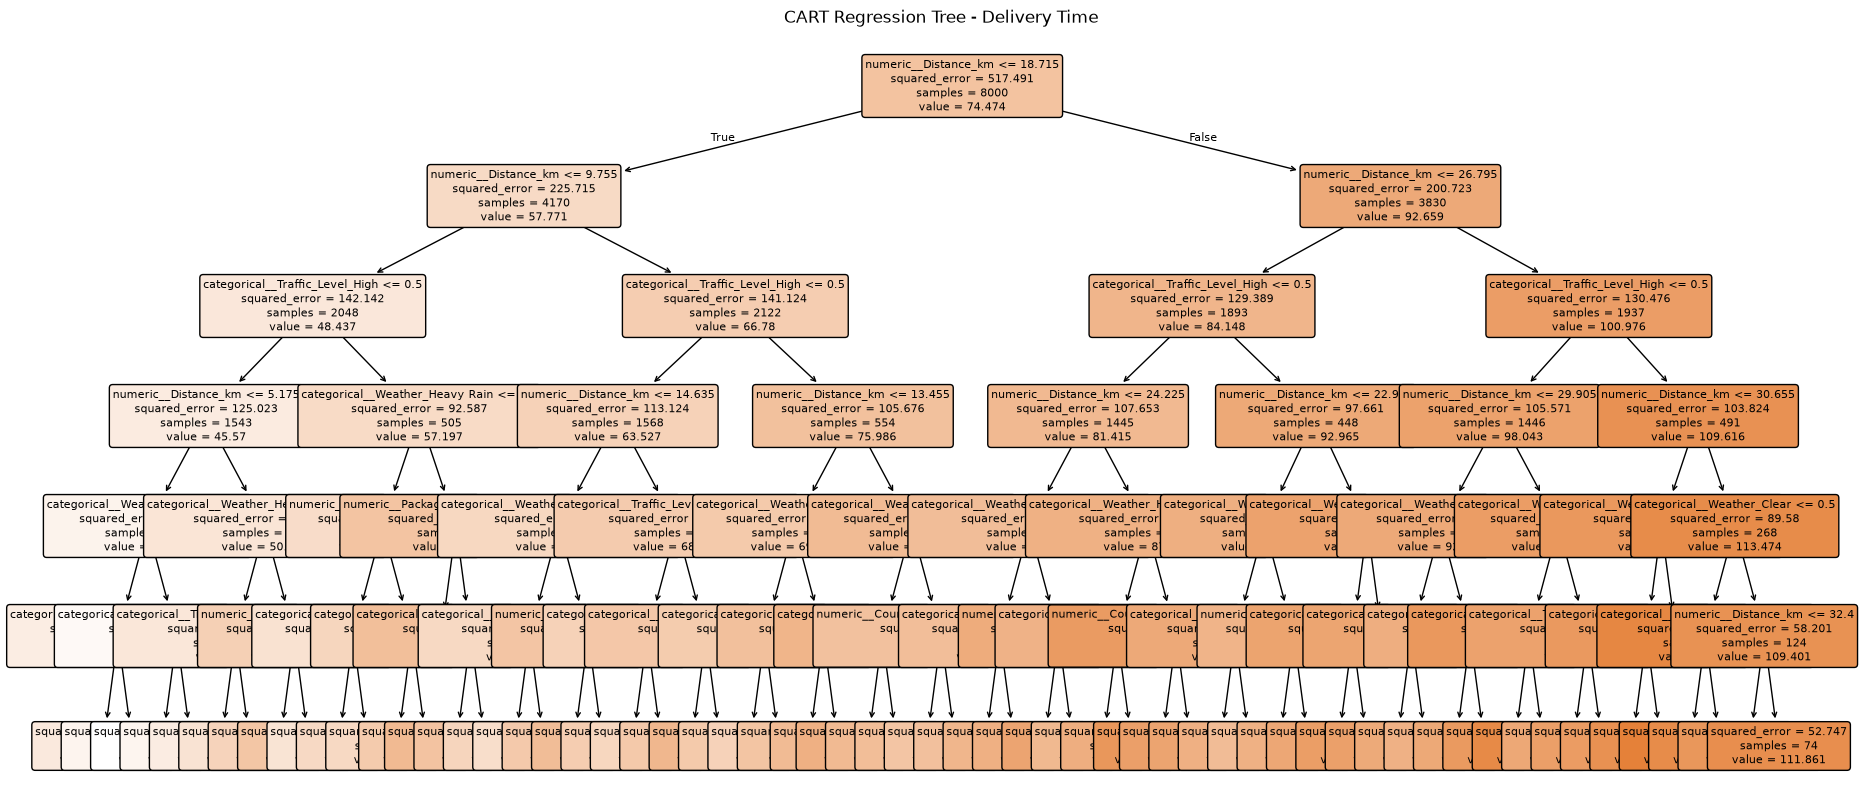

In [38]:
regression_features = cart_regressor.named_steps["preprocessor"].get_feature_names_out()
regression_tree = cart_regressor.named_steps["model"]

plt.figure(figsize=(22, 10))
plot_tree(regression_tree, feature_names=regression_features,
          filled=True, rounded=True, fontsize=8)
plt.title("CART Regression Tree - Delivery Time")
plt.show()

## 17. Actual vs predicted delivery time

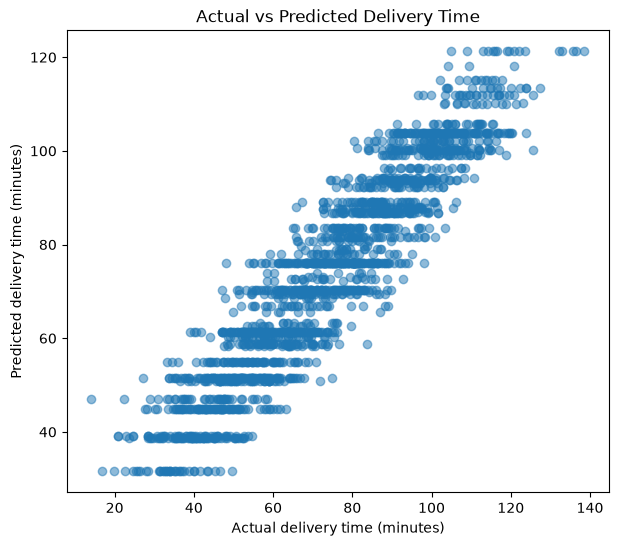

In [39]:
plt.figure(figsize=(7, 6))
plt.scatter(y_reg_test, y_reg_pred, alpha=0.5)
plt.xlabel("Actual delivery time (minutes)")
plt.ylabel("Predicted delivery time (minutes)")
plt.title("Actual vs Predicted Delivery Time")
plt.show()

## 18. Predict for a new delivery

In [40]:
new_delivery = pd.DataFrame([{
    "Distance_km": 12.5,
    "Weather": "Rain",
    "Traffic_Level": "High",
    "Vehicle_Type": "Bike",
    "City_Tier": "Tier 1",
    "Order_Hour": 19,
    "Package_Weight_kg": 4.2,
    "Courier_Experience_Years": 2,
    "Weekend_Order": "No"
}])

print("Predicted late delivery:", cart_classifier.predict(new_delivery)[0])
print("Predicted delivery time:",
      round(cart_regressor.predict(new_delivery)[0], 1), "minutes")

Predicted late delivery: Yes
Predicted delivery time: 79.8 minutes


## 19. CART: Classification vs Regression

| Aspect | Classification | Regression |
|---|---|---|
| Target | Late_Delivery (Yes/No) | Delivery_Time_Minutes |
| Model | DecisionTreeClassifier | DecisionTreeRegressor |
| Split criterion | Gini impurity | Squared error (MSE) |
| Output | Category | Number |
| Metrics | Accuracy, precision, recall, F1 | MAE, MSE, RMSE, R² |

## Key takeaways

- CART means Classification and Regression Trees.
- CART creates binary splits.
- Classification predicts a class; regression predicts a numeric value.
- One-hot encoding converts categorical input features into numeric columns.
- The CSV is synthetic learning data, not real company data.

**Practice:** Change `max_depth` to 3, 5, 8, and `None`. Compare the test metrics and observe overfitting.